# Heart Disease UCI — Exploratory Data Analysis (EDA)

**Goal:** understand the cleaned dataset before building models.

We look at:
1. Dataset overview (size, columns, types)
2. Missing values
3. Target class balance
4. Distributions of numeric features (histograms)
5. Correlation heatmap
6. How key features relate to the target

The data was produced by `src/preprocess.py` which merges the four UCI hospital
files, converts `?` to missing values, and creates a binary `target`
(0 = no disease, 1 = disease).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# Resolve project paths relative to this notebook (notebooks/ -> project root)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "heart.csv"
FIG_DIR = PROJECT_ROOT / "report" / "screenshots"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
df.head()

Loaded: /Users/nbn027/Downloads/Mlops/data/processed/heart.csv
Shape: (920, 15)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,source,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,cleveland,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,cleveland,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,cleveland,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,cleveland,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,cleveland,0


## 1. Dataset overview

`info()` shows column types and non-null counts; `describe()` gives summary
statistics for the numeric columns.

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       920 non-null    float64
 1   sex       920 non-null    float64
 2   cp        920 non-null    float64
 3   trestbps  861 non-null    float64
 4   chol      890 non-null    float64
 5   fbs       830 non-null    float64
 6   restecg   918 non-null    float64
 7   thalach   865 non-null    float64
 8   exang     865 non-null    float64
 9   oldpeak   858 non-null    float64
 10  slope     611 non-null    float64
 11  ca        309 non-null    float64
 12  thal      434 non-null    float64
 13  source    920 non-null    object 
 14  target    920 non-null    int64  
dtypes: float64(13), int64(1), object(1)
memory usage: 107.9+ KB


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,920.0,53.510870,9.424685,28.0,47.0,54.0,60.0,77.0
sex,920.0,0.789130,0.408148,0.0,1.0,1.0,1.0,1.0
cp,920.0,3.250000,0.930969,1.0,3.0,4.0,4.0,4.0
trestbps,861.0,132.132404,19.066070,0.0,120.0,130.0,140.0,200.0
chol,890.0,199.130337,110.780810,0.0,175.0,223.0,268.0,603.0
fbs,830.0,0.166265,0.372543,0.0,0.0,0.0,0.0,1.0
restecg,918.0,0.604575,0.805827,0.0,0.0,0.0,1.0,2.0
thalach,865.0,137.545665,25.926276,60.0,120.0,140.0,157.0,202.0
exang,865.0,0.389595,0.487941,0.0,0.0,0.0,1.0,1.0
oldpeak,858.0,0.878788,1.091226,-2.6,0.0,0.5,1.5,6.2


### Feature dictionary

| Feature | Meaning |
|---|---|
| age | age in years |
| sex | 1 = male, 0 = female |
| cp | chest pain type (1-4) |
| trestbps | resting blood pressure (mm Hg) |
| chol | serum cholesterol (mg/dl) |
| fbs | fasting blood sugar > 120 mg/dl (1/0) |
| restecg | resting ECG results (0-2) |
| thalach | max heart rate achieved |
| exang | exercise-induced angina (1/0) |
| oldpeak | ST depression induced by exercise |
| slope | slope of peak exercise ST segment (1-3) |
| ca | number of major vessels colored (0-3) |
| thal | thalassemia (3 = normal, 6 = fixed, 7 = reversible) |
| source | hospital the record came from |
| target | **1 = heart disease, 0 = none** |

In [4]:
# Records per hospital source
df["source"].value_counts()

source
cleveland      303
hungarian      294
va             200
switzerland    123
Name: count, dtype: int64

## 2. Missing values

Some features (`ca`, `thal`, `slope`) are missing in most non-Cleveland
records. We will impute these inside the model pipeline later.

          missing_count  missing_pct
ca                  611         66.4
thal                486         52.8
slope               309         33.6
fbs                  90          9.8
oldpeak              62          6.7
trestbps             59          6.4
thalach              55          6.0
exang                55          6.0
chol                 30          3.3
restecg               2          0.2
age                   0          0.0
sex                   0          0.0
cp                    0          0.0
source                0          0.0
target                0          0.0


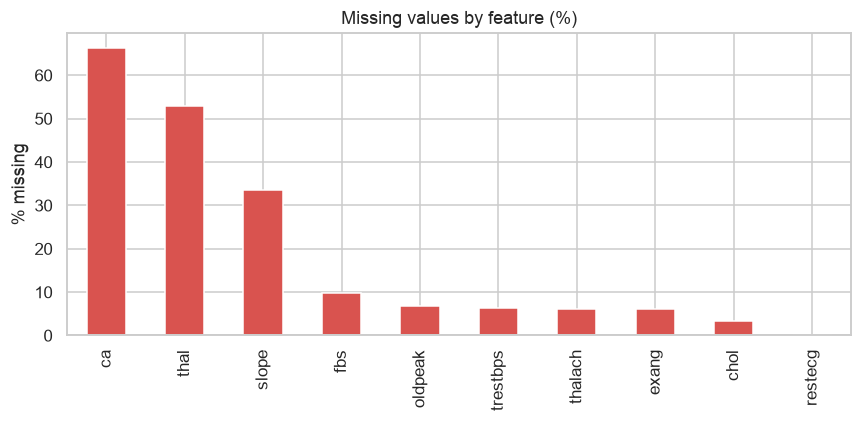

In [5]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(1)
missing_table = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
print(missing_table)

ax = missing_pct[missing_pct > 0].plot(kind="bar", color="#d9534f", figsize=(8, 4))
ax.set_title("Missing values by feature (%)")
ax.set_ylabel("% missing")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_missing_values.png", bbox_inches="tight")
plt.show()

## 3. Target class balance

A balanced target means accuracy is a reasonable metric (but we still report
precision/recall/ROC-AUC).

target
0    411
1    509
Name: count, dtype: int64

Proportion:
target
0    0.447
1    0.553
Name: count, dtype: float64


/var/folders/__/rhxbb0t57ml68xbcf_88382m0000gp/T/ipykernel_87175/2284719407.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="target", data=df, palette=["#5cb85c", "#d9534f"])
/var/folders/__/rhxbb0t57ml68xbcf_88382m0000gp/T/ipykernel_87175/2284719407.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["No disease (0)", "Disease (1)"])


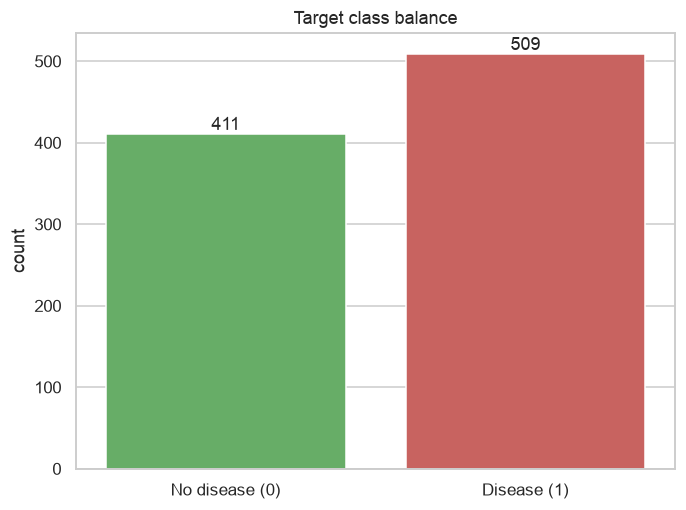

In [6]:
counts = df["target"].value_counts().sort_index()
print(counts)
print("\nProportion:")
print((counts / counts.sum()).round(3))

ax = sns.countplot(x="target", data=df, palette=["#5cb85c", "#d9534f"])
ax.set_xticklabels(["No disease (0)", "Disease (1)"])
ax.set_title("Target class balance")
ax.set_xlabel("")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_class_balance.png", bbox_inches="tight")
plt.show()

## 4. Distributions of numeric features (histograms)

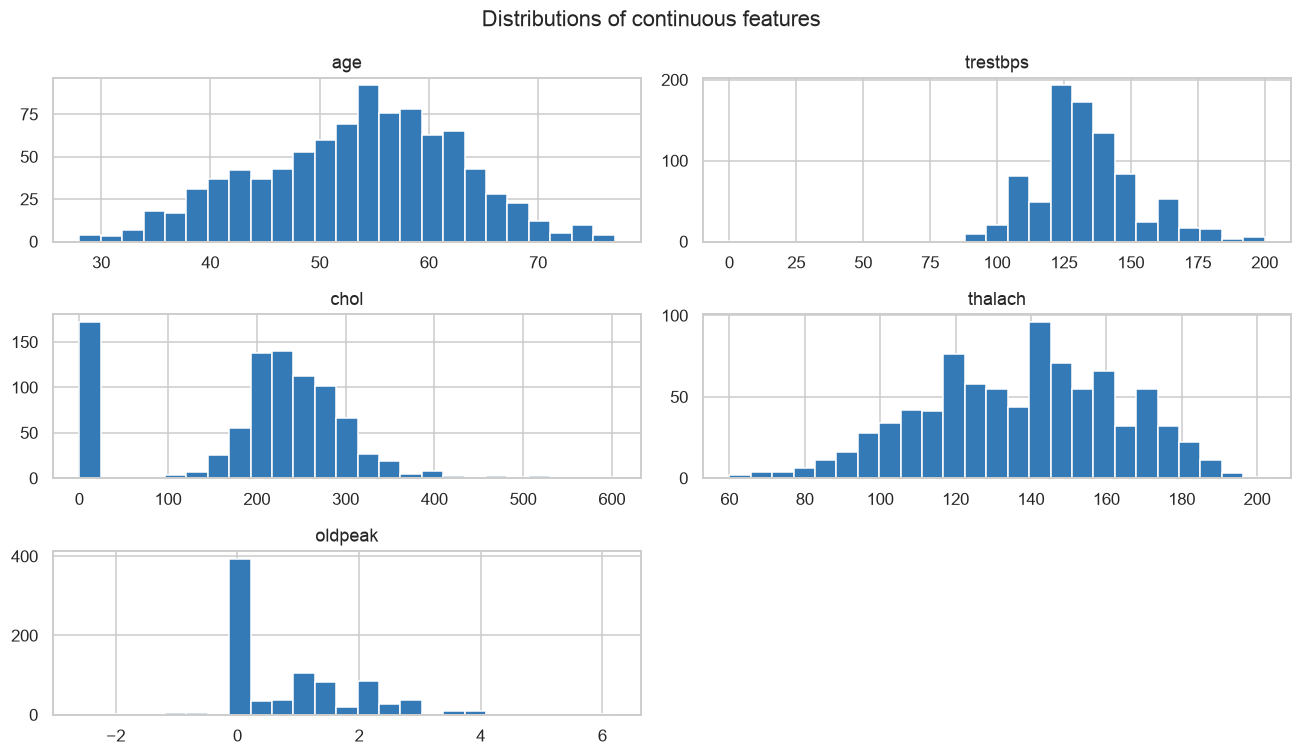

In [7]:
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
df[numeric_cols].hist(bins=25, figsize=(12, 7), color="#337ab7", edgecolor="white")
plt.suptitle("Distributions of continuous features")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_histograms.png", bbox_inches="tight")
plt.show()

**Note:** `chol` and `trestbps` contain some `0` values (physically impossible),
which represent recording errors in the non-Cleveland hospitals. We will treat
these during modeling.

## 5. Correlation heatmap

Shows linear relationships between features and with the target.

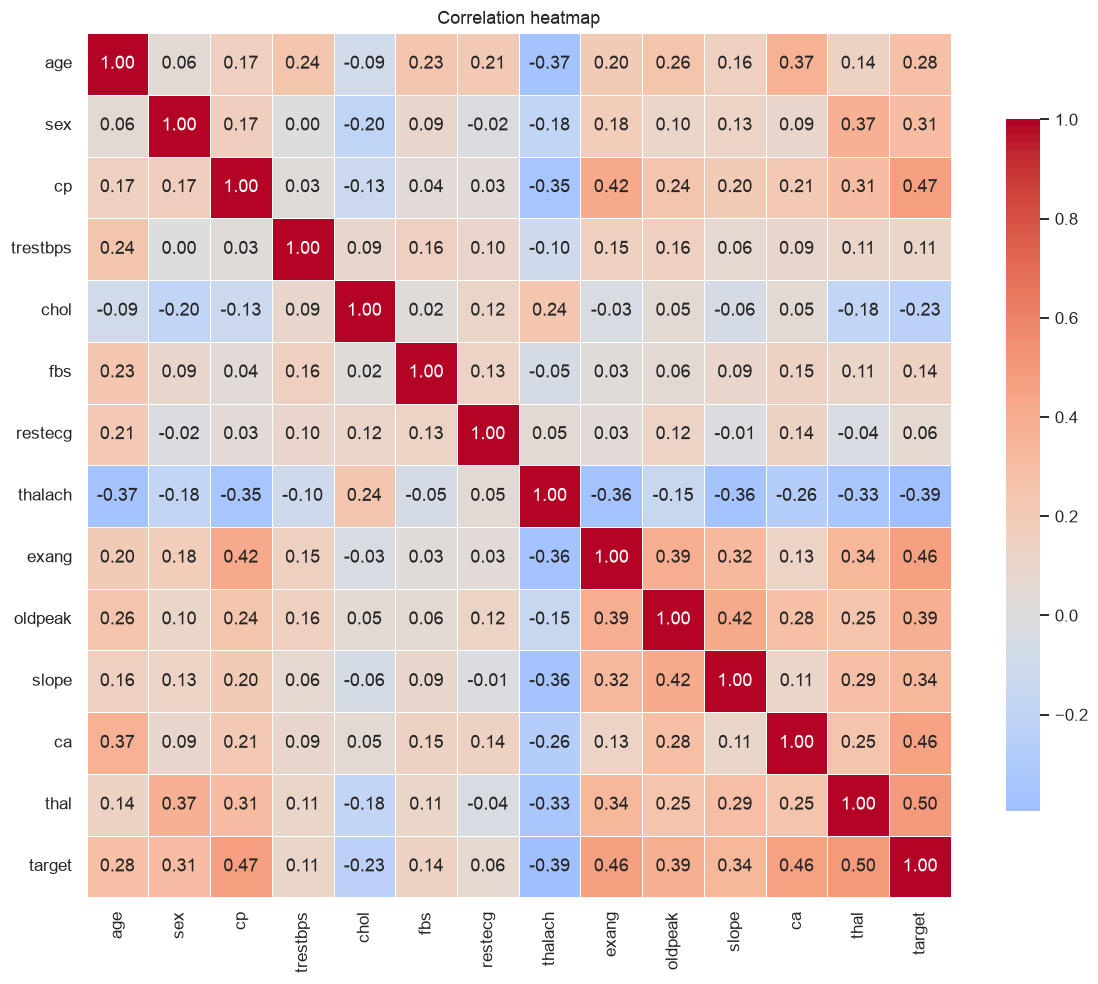

In [8]:
corr = df.drop(columns=["source"]).corr(numeric_only=True)
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_correlation_heatmap.png", bbox_inches="tight")
plt.show()

In [9]:
# Features most correlated with the target
corr["target"].drop("target").sort_values(key=abs, ascending=False)

thal        0.498521
cp          0.471712
exang       0.463619
ca          0.455599
thalach    -0.394503
oldpeak     0.385528
slope       0.337086
sex         0.307284
age         0.282700
chol       -0.230583
fbs         0.142565
trestbps    0.106233
restecg     0.063867
Name: target, dtype: float64

## 6. Key features vs target

/var/folders/__/rhxbb0t57ml68xbcf_88382m0000gp/T/ipykernel_87175/3364023448.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="target", y="age", data=df, ax=axes[0, 0], palette=["#5cb85c", "#d9534f"])
/var/folders/__/rhxbb0t57ml68xbcf_88382m0000gp/T/ipykernel_87175/3364023448.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="target", y="thalach", data=df, ax=axes[0, 1], palette=["#5cb85c", "#d9534f"])


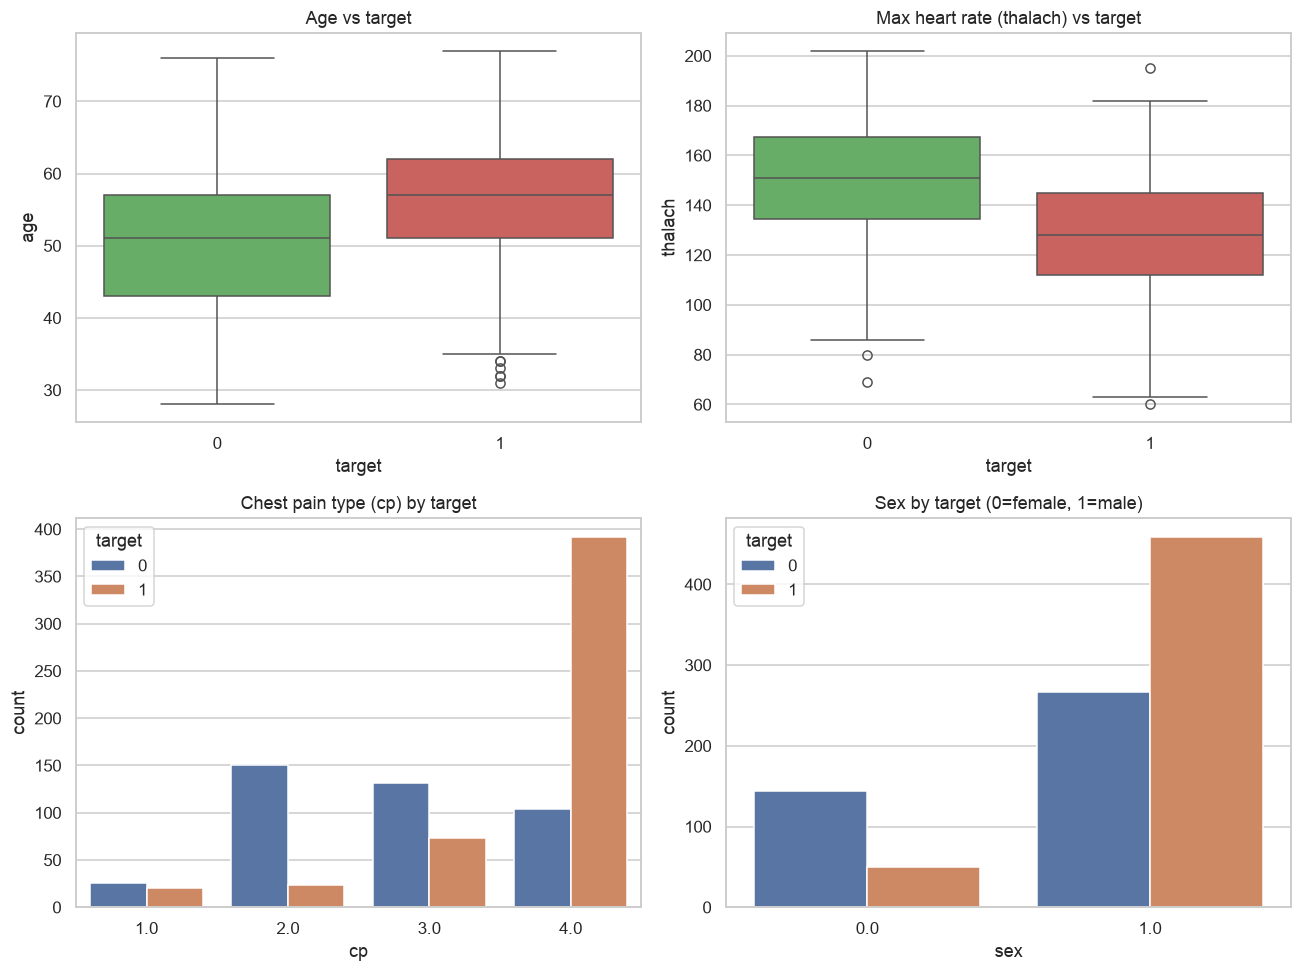

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.boxplot(x="target", y="age", data=df, ax=axes[0, 0], palette=["#5cb85c", "#d9534f"])
axes[0, 0].set_title("Age vs target")

sns.boxplot(x="target", y="thalach", data=df, ax=axes[0, 1], palette=["#5cb85c", "#d9534f"])
axes[0, 1].set_title("Max heart rate (thalach) vs target")

sns.countplot(x="cp", hue="target", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Chest pain type (cp) by target")

sns.countplot(x="sex", hue="target", data=df, ax=axes[1, 1])
axes[1, 1].set_title("Sex by target (0=female, 1=male)")

plt.tight_layout()
plt.savefig(FIG_DIR / "eda_feature_vs_target.png", bbox_inches="tight")
plt.show()

## 7. Summary of findings

- **~920 patients**, target is fairly balanced (~55% disease / ~45% none).
- **`ca`, `thal`, `slope`** have heavy missingness → need imputation.
- **`chol` / `trestbps`** contain impossible `0` values in some hospitals.
- Features most related to disease typically include **`cp`, `oldpeak`, `thalach`,
  `exang`, `ca`, `thal`** — these align with medical intuition.
- Next step (`src/train.py`): build a preprocessing pipeline (impute + scale)
  and train Logistic Regression and Random Forest with MLflow tracking.

All figures are saved under `report/screenshots/` for the final report.